# 5 Exploration (optional)

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import sklearn


import torch
import torch.nn
import torch.utils.data
import torch.nn.functional

%load_ext autoreload
%autoreload 2

from a02_helper import *
from a02_functions import optimize

### 5 Exploration: PyTorch

In [2]:
# If you want to experiment, here is an implementation of logistic regression in PyTorch

# prepare the data
Xztorch = torch.FloatTensor(Xz)
ytorch = torch.LongTensor(y)
train = torch.utils.data.TensorDataset(Xztorch, ytorch)


# manual implementation of logistic regression (without bias)
class LogisticRegression(torch.nn.Module):
    def __init__(self, D, C):
        super(LogisticRegression, self).__init__()
        self.weights = torch.nn.Parameter(
            torch.randn(D, C) / math.sqrt(D)
        )  # xavier initialization
        self.register_parameter("W", self.weights)

    def forward(self, x):
        out = torch.matmul(x, self.weights)
        out = torch.nn.functional.log_softmax(out, dim=1)
        return out


# define the objective and update function. here we ignore the learning rates and
# parameters given to us by optimize (they are stored in the PyTorch model and
# optimizer, resp., instead)
def opt_pytorch():
    model = LogisticRegression(D, 2)
    criterion = torch.nn.NLLLoss(reduction="mean")
    # change the next line to try different optimizers
    # optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    def objective(_):
        outputs = model(Xztorch)
        return criterion(outputs, ytorch).item()

    def update(_1, _2):
        for i, (examples, labels) in enumerate(train_loader):
            outputs = model(examples)
            loss = criterion(outputs, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        W = model.state_dict()["W"]
        w = W[:, 1] - W[:, 0]
        return w

    return (objective, update)

The following added setup fixes the PyTorch initialization seed so this optional run is reproducible.

In [3]:
_ = torch.manual_seed(0)

In [4]:
# run the optimizer
learning_rate = 0.01
batch_size = 100  # number of data points to sample for gradient estimate
shuffle = True  # sample with replacement (false) or without replacement (true)

train_loader = torch.utils.data.DataLoader(train, batch_size, shuffle=True)
wz_t, vz_t, _ = optimize(opt_pytorch(), None, nepochs=100, eps0=learning_rate, verbose=False)

## Optional comparison: PyTorch Adam versus the assignment GD and SGD fits

This added analysis compares test-set mean log-loss and accuracy on the same normalized data. The PyTorch run uses 100 mini-batch epochs with Adam (learning rate 0.01); the assignment GD and SGD baselines use 500 epochs through the supplied `optimize` framework. Because their epoch and update budgets differ, this is an exploratory comparison rather than a controlled convergence-speed comparison.

In [5]:
import pandas as pd
from a02_functions import er, gd_er, sgd_er, sigma

# Fit the assignment's GD and SGD methods on the same normalized training data.
np.random.seed(0)
w0_gd = np.random.normal(size=D)
wz_gd, _, _ = optimize(gd_er(y, Xz), w0_gd, nepochs=500, verbose=False)

np.random.seed(0)
w0_sgd = np.random.normal(size=D)
wz_sgd, _, _ = optimize(sgd_er(y, Xz), w0_sgd, nepochs=500, verbose=False)

models_task5 = {
    "PyTorch Adam (100 epochs)": wz_t.detach().cpu().numpy(),
    "GD (500 epochs)": wz_gd,
    "SGD (500 epochs)": wz_sgd,
}
rows_task5 = []
for name, weights in models_task5.items():
    test_probabilities = sigma(Xtestz @ weights)
    test_labels = (test_probabilities >= 0.5).astype(int)
    rows_task5.append({
        "method": name,
        "training empirical risk": er(y, Xz, weights),
        "test mean log-loss": er(ytest, Xtestz, weights),
        "test accuracy": np.mean(test_labels == ytest),
    })

results_task5 = pd.DataFrame(rows_task5).set_index("method")
print(results_task5.round(6).to_string())

                           training empirical risk  test mean log-loss  test accuracy
method                                                                               
PyTorch Adam (100 epochs)                 0.211608            0.275112       0.918620
GD (500 epochs)                           0.214451            0.279155       0.918620
SGD (500 epochs)                          0.216413            0.282740       0.917318


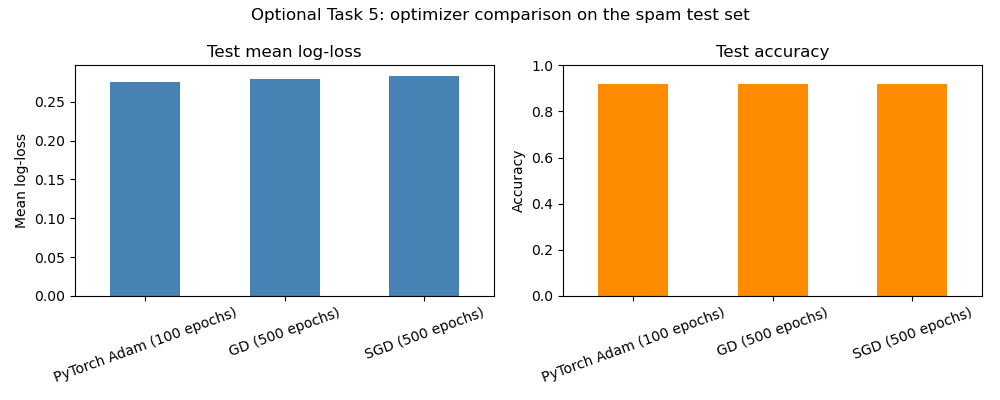

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
results_task5["test mean log-loss"].plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Test mean log-loss", ylabel="Mean log-loss", xlabel="")
axes[0].tick_params(axis="x", rotation=20)
results_task5["test accuracy"].plot.bar(ax=axes[1], color="darkorange")
axes[1].set(title="Test accuracy", ylabel="Accuracy", xlabel="", ylim=(0, 1))
axes[1].tick_params(axis="x", rotation=20)
fig.suptitle("Optional Task 5: optimizer comparison on the spam test set")
fig.tight_layout()
plt.show()

### Observations

On this run, PyTorch Adam achieved training empirical risk 0.211608, test mean log-loss 0.275112, and test accuracy 0.918620. GD achieved 0.214451, 0.279155, and 0.918620; SGD achieved 0.216413, 0.282740, and 0.917318. Thus Adam had the lowest recorded training and test log-loss here, matched GD accuracy, and was slightly more accurate than SGD. This is a descriptive comparison, not a controlled benchmark: Adam starts from a seeded PyTorch D-by-2 weight matrix, whereas GD and SGD start from the same seeded NumPy D-vector; the update budgets also differ (Adam: 100 epochs x 31 mini-batches = 3,100 minibatch updates; GD: 500 full-batch updates; SGD: 500 passes over 3,065 examples = 1,532,500 per-example updates). The observations apply to this run and do not establish that Adam is generally superior.